# Homework II - Grupo 001 - Aprendizagem 2026/2027 
**Parte II - Programming and critical analysis**

### Imports e Carregamento de Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, recall_score
from lime.lime_tabular import LimeTabularExplainer

# Carregar o dataset
df = pd.read_csv('heart.csv')

# Separar features (X) e target (y)
X = df.drop(columns=['outcome'])
y = df['outcome']
features = X.columns.tolist()


## **Exercício 1:** Cross-Validation e Pipelines

In [2]:
# Definir a estratégia de validação cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scoring = {'accuracy': 'accuracy', 'recall': make_scorer(recall_score, pos_label=1)}

# --- 1a. Modelos sem escalamento ---
knn_base = KNeighborsClassifier(n_neighbors=5)
gnb_base = GaussianNB()

res_knn_base = cross_validate(knn_base, X, y, cv=cv, scoring=scoring)
res_gnb_base = cross_validate(gnb_base, X, y, cv=cv, scoring=scoring)

print("--- 1a. Sem Escalamento ---")
print(f"kNN - Accuracy: {res_knn_base['test_accuracy'].mean():.4f} +/- {res_knn_base['test_accuracy'].std():.4f}")
print(f"kNN - Recall:   {res_knn_base['test_recall'].mean():.4f} +/- {res_knn_base['test_recall'].std():.4f}")
print(f"GNB - Accuracy: {res_gnb_base['test_accuracy'].mean():.4f} +/- {res_gnb_base['test_accuracy'].std():.4f}")
print(f"GNB - Recall:   {res_gnb_base['test_recall'].mean():.4f} +/- {res_gnb_base['test_recall'].std():.4f}\n")

# --- 1b. Modelos com MinMaxScaler ---
pipe_knn = Pipeline([('scaler', MinMaxScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])
pipe_gnb = Pipeline([('scaler', MinMaxScaler()), ('gnb', GaussianNB())])

res_knn_pipe = cross_validate(pipe_knn, X, y, cv=cv, scoring=scoring)
res_gnb_pipe = cross_validate(pipe_gnb, X, y, cv=cv, scoring=scoring)

print("--- 1b. Com MinMaxScaler ---")
print(f"kNN - Accuracy: {res_knn_pipe['test_accuracy'].mean():.4f} +/- {res_knn_pipe['test_accuracy'].std():.4f}")
print(f"kNN - Recall:   {res_knn_pipe['test_recall'].mean():.4f} +/- {res_knn_pipe['test_recall'].std():.4f}")
print(f"GNB - Accuracy: {res_gnb_pipe['test_accuracy'].mean():.4f} +/- {res_gnb_pipe['test_accuracy'].std():.4f}")
print(f"GNB - Recall:   {res_gnb_pipe['test_recall'].mean():.4f} +/- {res_gnb_pipe['test_recall'].std():.4f}")

--- 1a. Sem Escalamento ---
kNN - Accuracy: 0.5915 +/- 0.0329
kNN - Recall:   0.3286 +/- 0.0885
GNB - Accuracy: 0.8167 +/- 0.0360
GNB - Recall:   0.7662 +/- 0.0410

--- 1b. Com MinMaxScaler ---
kNN - Accuracy: 0.7920 +/- 0.0453
kNN - Recall:   0.6295 +/- 0.0802
GNB - Accuracy: 0.8167 +/- 0.0360
GNB - Recall:   0.7662 +/- 0.0410


##### **1a. Avaliação e Estabilidade:**
- **Desempenho:** o Naïve Bayes é claramente melhor que o kNN (Accuracy de ~81.7% vs ~59.2% e Recall de ~76.6% vs ~32.9%). Sem escalamento, o kNN deteta menos de um terço dos doentes.
- **Estabilidade:** na Accuracy os desvios padrão são comparáveis (0.036 no NB vs 0.033 no kNN). No Recall a diferença é grande (0.041 vs 0.089), logo o NB é o modelo mais estável, sobretudo na deteção da classe positiva.

##### **1b. Impacto do MinMaxScaler:**
- **No kNN:** impacto muito positivo (Accuracy de ~59.2% para ~79.2% e Recall de ~32.9% para ~63.0%). Sem escalamento, as variáveis de maior amplitude (`thalach`, `trestbps`, `age`) dominam a distância euclidiana e as de pequena escala (`sex`, `chest_pain`, `oldpeak`) quase não contribuem. Com o Min-Max todas ficam em $[0,1]$ e passam a contar para a escolha dos vizinhos. Dentro da pipeline, o scaler é ajustado só ao treino de cada fold, sem fuga de informação.
- **No Naïve Bayes:** impacto nulo (resultados idênticos). Uma transformação linear $x' = (x-a)/b$ altera a média para $(\mu-a)/b$ e a variância para $\sigma^2/b^2$, e multiplica a verosimilhança de cada variável pela mesma constante $1/b$ nas duas classes. Essa constante cancela-se na comparação das posteriores, por isso a classe prevista não muda.
- Todos os parâmetros opcionais foram mantidos por omissão (exceto $k=5$, pedido no enunciado).

## **Exercício 2:** Split 70-30 Avaliação de k e Gráficos

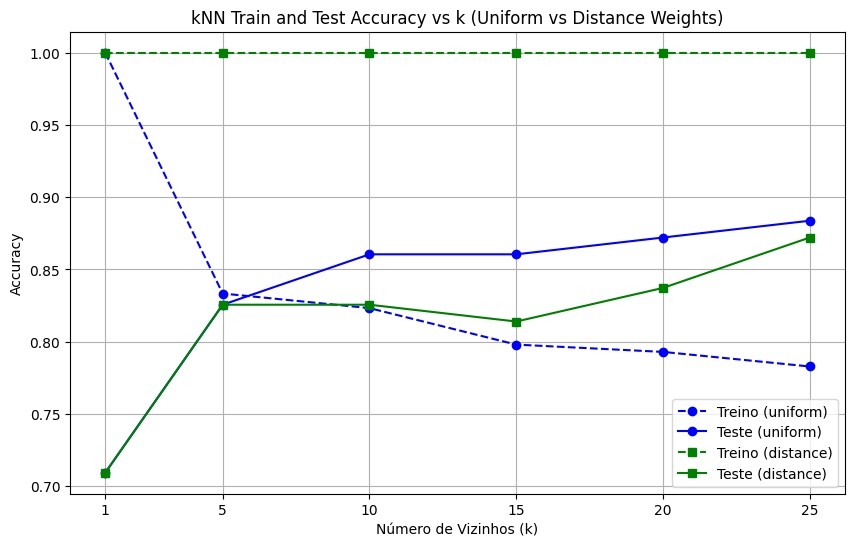

In [3]:
# Split estratificado 70-30
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=0
)

k_values = [1, 5, 10, 15, 20, 25]
weights_list = ['uniform', 'distance']
results = []

for w in weights_list:
    for k in k_values:
        pipe = Pipeline([
            ('scaler', MinMaxScaler()), 
            ('knn', KNeighborsClassifier(n_neighbors=k, weights=w))
        ])
        pipe.fit(X_train, y_train)
        
        results.append({
            'weights': w, 
            'k': k,
            'train_acc': pipe.score(X_train, y_train),
            'test_acc': pipe.score(X_test, y_test)
        })

df_res = pd.DataFrame(results)

# Plotting
plt.figure(figsize=(10, 6))

for w, color, style in [('uniform', 'blue', 'o'), ('distance', 'green', 's')]:
    subset = df_res[df_res['weights'] == w]
    plt.plot(subset['k'], subset['train_acc'], f'{style}--', label=f'Treino ({w})', color=color)
    plt.plot(subset['k'], subset['test_acc'], f'{style}-', label=f'Teste ({w})', color=color)

plt.xlabel('Número de Vizinhos (k)')
plt.ylabel('Accuracy')
plt.title('kNN Train and Test Accuracy vs k (Uniform vs Distance Weights)')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()  

##### **Alínea 2.b: Trade-offs do kNN e Valor Ótimo**

##### **Impacto do aumento de $k$:**
- **$k$ pequeno ($k=1$):** viés baixo e variância muito alta. Atinge 100% de Accuracy no treino mas só ~70.9% no teste, porque memoriza o ruído do treino (*overfitting*).
- **$k$ crescente:** a fronteira de decisão fica mais suave. O viés aumenta (Accuracy de treino com pesos uniformes desce de ~83% para ~78%) e a variância diminui (Accuracy de teste sobe de ~83% para ~88%), porque cada previsão depende de mais vizinhos e é menos sensível a pontos ruidosos.
- **$k$ demasiado grande:** haveria *underfitting* (a classe maioritária domina), mas isso ainda não é visível na grelha testada, pois o teste continua a subir até $k=25$.

##### **Pesos (Uniforme vs Distância):**
- Com pesos por distância, a Accuracy de treino é sempre 100%, porque cada ponto de treino é o seu próprio vizinho a distância 0. O modelo não beneficia da regularização que um $k$ elevado traz e comporta-se quase como um 1-NN.
- Para $k \ge 10$, os pesos uniformes têm melhor teste (0.86-0.88) do que os pesos por distância (0.81-0.87).

##### **Valor ótimo:**
- Sugere-se o **intervalo $k \in [10, 25]$ com pesos uniformes**, com preferência pela parte alta (20-25, teste de ~87-88%).
- Não se escolhe um único valor porque o teste tem só 86 pacientes (1 paciente ≈ 1.2 pontos percentuais), e entre $k=10$ e $k=25$ a diferença é de apenas 2 pacientes. Além disso, $k=25$ é o limite da grelha, pelo que o ótimo pode estar acima. Fixar $k$ com base num único split seria *overfitting* ao conjunto de teste.

## **Exercício 3:** Preparação para o LIME

In [4]:
# Treinar os modelos finais com k=5 no conjunto de treino
pipe_knn.fit(X_train, y_train)
pipe_gnb.fit(X_train, y_train)

# Previsões para encontrar TP e FN
pred_knn = pipe_knn.predict(X_test)
pred_gnb = pipe_gnb.predict(X_test)

# Reset aos índices do X_test para facilitar a extração das linhas
X_test_reset = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)

df_eval = pd.DataFrame({
    'true_y': y_test_reset,
    'pred_knn': pred_knn,
    'pred_gnb': pred_gnb
})

### **Alínea 3.a:** Primeiro Verdadeiro Positivo

Paciente 3a (índice 1 no teste):
age                        52.0
sex                         1.0
chest_pain                  4.0
trestbps                  112.0
fasting_blood_sugar         0.0
restecg                     1.0
thalach                    96.0
exercise_induce_angina      1.0
oldpeak                     1.0
Name: 1, dtype: float64

--- LIME: kNN (Paciente 3a) ---
Fidelity Score (R^2): 0.5373
0.00 < exercise_induce_angina <= 1.00    +0.2896
3.00 < chest_pain <= 4.00                +0.2648
fasting_blood_sugar <= 0.00              -0.2546
0.00 < sex <= 1.00                       +0.2117
thalach <= 120.00                        +0.0321


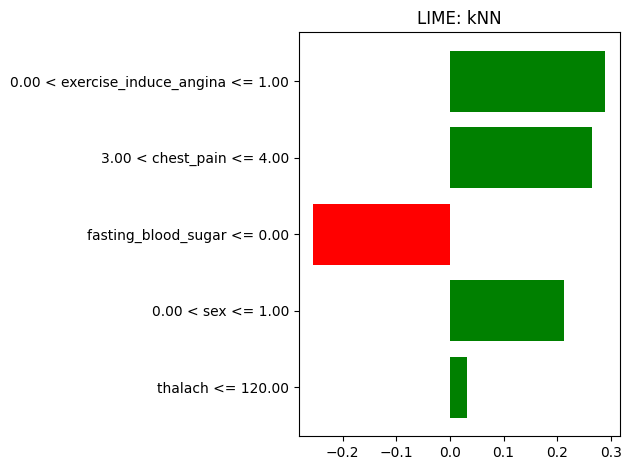


--- LIME: Naïve Bayes (Paciente 3a) ---
Fidelity Score (R^2): 0.4538
fasting_blood_sugar <= 0.00              -0.6763
0.00 < exercise_induce_angina <= 1.00    +0.3741
0.00 < sex <= 1.00                       +0.2657
3.00 < chest_pain <= 4.00                +0.1679
restecg > 0.00                           -0.1283


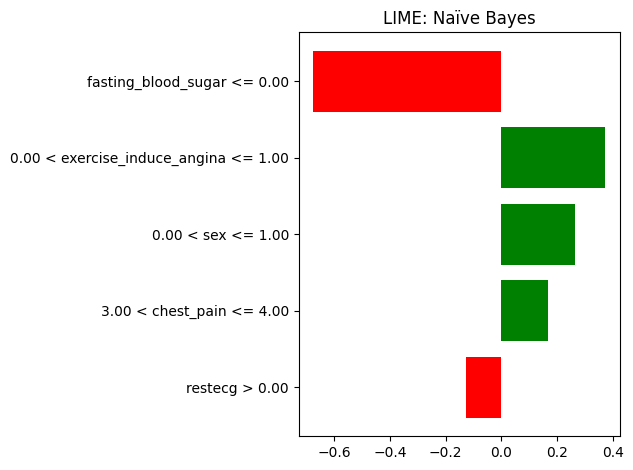


--- GaussianNB: Parâmetros para 'fasting_blood_sugar' ---
Classe 0 (Saudável) - Média: 0.0238 | Variância: 0.0232
Classe 1 (Doente)   - Média: 0.1389 | Variância: 0.1196


In [5]:
# Função explain do enunciado, com duas alterações (os restantes parâmetros ficam por omissão):
#  1) O LIME recebe X_train.values (array numpy) em vez do DataFrame, e x.values em vez da Series.
#     Com DataFrame/Series o LIME falha (KeyError: 0) ao indexar por posição.
#  2) As amostras perturbadas que o LIME gera são arrays numpy, mas as pipelines foram treinadas
#     com DataFrames com nomes de colunas; por isso reconstruímos um DataFrame antes de chamar
#     predict_proba (evita warnings e mantém a pipeline completa, com o MinMaxScaler).
# As explicações referem-se assim aos valores originais (não escalados) das variáveis.
def explain(model, x, seed=0, num_samples=5000):
    explainer = LimeTabularExplainer(
        X_train.values,
        feature_names=features,
        class_names=["no disease", "disease"],
        mode="classification",
        random_state=seed
    )

    def predict_with_names(array_data):
        df_temp = pd.DataFrame(array_data, columns=features)
        return model.predict_proba(df_temp)

    return explainer.explain_instance(
        x.values if isinstance(x, pd.Series) else x,
        predict_with_names,
        num_features=5,
        num_samples=num_samples
    )

# Primeira linha do teste que é Verdadeiro Positivo para ambos os modelos
mask_tp = (df_eval['true_y'] == 1) & (df_eval['pred_knn'] == 1) & (df_eval['pred_gnb'] == 1)
idx_tp = df_eval[mask_tp].index[0]
x_3a = X_test_reset.iloc[idx_tp]

print(f"Paciente 3a (índice {idx_tp} no teste):\n{x_3a}\n")

# LIME para o kNN
exp_knn_3a = explain(pipe_knn, x_3a)
print("--- LIME: kNN (Paciente 3a) ---")
print(f"Fidelity Score (R^2): {exp_knn_3a.score:.4f}")
for cond, weight in exp_knn_3a.as_list():
    print(f"{cond:40s} {weight:+.4f}")
exp_knn_3a.as_pyplot_figure()
plt.title("LIME: kNN")
plt.tight_layout()
plt.show()

# LIME para o Naïve Bayes
exp_gnb_3a = explain(pipe_gnb, x_3a)
print("\n--- LIME: Naïve Bayes (Paciente 3a) ---")
print(f"Fidelity Score (R^2): {exp_gnb_3a.score:.4f}")
for cond, weight in exp_gnb_3a.as_list():
    print(f"{cond:40s} {weight:+.4f}")
exp_gnb_3a.as_pyplot_figure()
plt.title("LIME: Naïve Bayes")
plt.tight_layout()
plt.show()

# Média e variância estimadas pelo GaussianNB (após o MinMaxScaler) para fasting_blood_sugar
gnb_model = pipe_gnb.named_steps['gnb']
idx_fbs = features.index('fasting_blood_sugar')

print("\n--- GaussianNB: Parâmetros para 'fasting_blood_sugar' ---")
print(f"Classe 0 (Saudável) - Média: {gnb_model.theta_[0][idx_fbs]:.4f} | Variância: {gnb_model.var_[0][idx_fbs]:.4f}")
print(f"Classe 1 (Doente)   - Média: {gnb_model.theta_[1][idx_fbs]:.4f} | Variância: {gnb_model.var_[1][idx_fbs]:.4f}")

##### **Alínea 3.a: Verdadeiro Positivo (paciente 1 do teste)**

- **Evidência partilhada:** os dois modelos baseiam-se nas mesmas condições: `exercise_induce_angina = 1`, `chest_pain = 4` e `sex = 1` empurram para "doença", e `fasting_blood_sugar = 0` empurra para "saudável". As diferenças são marginais (`thalach ≤ 120` só no kNN, `restecg > 0` só no NB).

- **Peso de `fasting_blood_sugar` no NB (−0.68 vs −0.26 no kNN):** o GaussianNB estimou μ = 0.024 e σ² = 0.023 na classe saudável, e μ = 0.139 e σ² = 0.120 na doente.

- Como a variável é quase sempre 0 nos saudáveis, a gaussiana desta classe é muito estreita, e as amostras perturbadas com valor 1 ficam muito penalizadas (≈ 20 nats nos saudáveis contra ≈ 3 nos doentes). Isto favorece fortemente "doente", e esta variável pode inverter a previsão do NB.

- No kNN é apenas uma das 9 dimensões da distância, com impacto limitado.

### **Alínea 3.b:** Primeiro Falso Negativo

In [6]:
# Encontrar a primeira linha que é Falso Negativo para pelo menos um modelo (Doente, mas previsto 0)
mask_fn = (df_eval['true_y'] == 1) & ((df_eval['pred_knn'] == 0) | (df_eval['pred_gnb'] == 0))
idx_fn = df_eval[mask_fn].index[0]
x_3b = X_test_reset.iloc[idx_fn]

print(f"Paciente 3b (índice {idx_fn} no teste):\n{x_3b}\n")
print(f"Previsões reais - kNN: {df_eval.loc[idx_fn, 'pred_knn']} | GNB: {df_eval.loc[idx_fn, 'pred_gnb']}\n")

exp_knn_3b = explain(pipe_knn, x_3b)
print("--- LIME: kNN (Paciente 3b) ---")
print(f"Fidelity Score (R^2): {exp_knn_3b.score:.4f}")
for cond, weight in exp_knn_3b.as_list():
    print(f"{cond:30s} {weight:+.4f}")
    
exp_gnb_3b = explain(pipe_gnb, x_3b)
print("\n--- LIME: Naïve Bayes (Paciente 3b) ---")
print(f"Fidelity Score (R^2): {exp_gnb_3b.score:.4f}")
for cond, weight in exp_gnb_3b.as_list():
    print(f"{cond:30s} {weight:+.4f}")

Paciente 3b (índice 3 no teste):
age                        39.0
sex                         1.0
chest_pain                  4.0
trestbps                  110.0
fasting_blood_sugar         0.0
restecg                     0.0
thalach                   150.0
exercise_induce_angina      0.0
oldpeak                     0.0
Name: 3, dtype: float64

Previsões reais - kNN: 0 | GNB: 0

--- LIME: kNN (Paciente 3b) ---
Fidelity Score (R^2): 0.5722
exercise_induce_angina <= 0.00 -0.2875
3.00 < chest_pain <= 4.00      +0.2712
fasting_blood_sugar <= 0.00    -0.2488
0.00 < sex <= 1.00             +0.2072
oldpeak <= 0.00                -0.1234

--- LIME: Naïve Bayes (Paciente 3b) ---
Fidelity Score (R^2): 0.6344
fasting_blood_sugar <= 0.00    -0.6844
oldpeak <= 0.00                -0.3892
exercise_induce_angina <= 0.00 -0.3702
0.00 < sex <= 1.00             +0.2521
3.00 < chest_pain <= 4.00      +0.1557


##### **Alínea 3.b: Falso Negativo (paciente 3 do teste)**

- **Condições que empurraram para a classe errada:** o paciente tem doença mas ambos os modelos preveem "saudável" (kNN: P(doença) = 0.40; NB: P(doença) = 0.05). As condições com peso negativo, isto é, que afastam da doença, são `exercise_induce_angina = 0`, `fasting_blood_sugar = 0` e `oldpeak = 0` (kNN: −0.29, −0.25 e −0.12; NB: −0.37, −0.68 e −0.39). `chest_pain = 4` e `sex = 1` empurram para "doença" (kNN: +0.27 e +0.21; NB: +0.16 e +0.25), mas são superados pelas três primeiras.

- **Fidelidade:** R² = 0.57 (kNN) e R² = 0.63 (NB). O modelo linear do LIME explica só cerca de 60% do comportamento local dos modelos.

- **A explicação é de confiança?** Só parcialmente. As duas explicações coincidem nas condições principais, o que lhes dá alguma credibilidade, mas com R² moderado ficam ~40% do comportamento por explicar, e a explicação descreve o que o modelo faz, não se está certo.

- **Como um clínico podia suspeitar do erro:** o modelo apoia-se na *ausência* de sinais (sem angina induzida, glicemia normal, `oldpeak = 0`), que é evidência clínica fraca, e dá pouco peso a um doente masculino com dor torácica assintomática (`chest_pain = 4`), um perfil de risco. A confiança também é suspeita: o NB dá 95% a "saudável" apesar de duas condições de risco, enquanto o kNN estava no limite (0.40/0.60).

### **Alínea 3.c:** Estabilidade do LIME

In [7]:
import numpy as np

# 1. Recuperar o x_3a (Primeiro Verdadeiro Positivo) para garantir que está na memória
mask_tp = (df_eval['true_y'] == 1) & (df_eval['pred_knn'] == 1) & (df_eval['pred_gnb'] == 1)
idx_tp = df_eval[mask_tp].index[0]
x_3a = X_test_reset.iloc[idx_tp]

# 2. Código da estabilidade do LIME
for N in [500, 5000]:
    feature_weights = {}
    top_5_counts = {}
    
    # Gerar 10 explicações mudando a seed
    for seed in range(10):
        exp = explain(pipe_knn, x_3a, seed=seed, num_samples=N)
        for condition, weight in exp.as_list():
            # Extrair apenas o nome da variável limpo
            feature_name = condition.split()[0]
            if feature_name.replace('.', '').isdigit(): # Caso o valor venha primeiro
                feature_name = condition.split()[2]
                
            top_5_counts[feature_name] = top_5_counts.get(feature_name, 0) + 1
            feature_weights.setdefault(feature_name, []).append(weight)
            
    print(f"\n===== Estabilidade kNN (Paciente 3a) com N = {N} =====")
    for feat in top_5_counts:
        std_dev = np.std(feature_weights[feat]) if len(feature_weights[feat]) > 1 else 0.0
        print(f"Variável: {feat:25s} | Frequência Top-5: {top_5_counts[feat]:2d}/10 | Desvio Padrão Pesos: {std_dev:.4f}")


===== Estabilidade kNN (Paciente 3a) com N = 500 =====
Variável: chest_pain                | Frequência Top-5: 10/10 | Desvio Padrão Pesos: 0.0201
Variável: exercise_induce_angina    | Frequência Top-5: 10/10 | Desvio Padrão Pesos: 0.0248
Variável: sex                       | Frequência Top-5: 10/10 | Desvio Padrão Pesos: 0.0173
Variável: fasting_blood_sugar       | Frequência Top-5: 10/10 | Desvio Padrão Pesos: 0.0379
Variável: oldpeak                   | Frequência Top-5:  2/10 | Desvio Padrão Pesos: 0.0081
Variável: trestbps                  | Frequência Top-5:  1/10 | Desvio Padrão Pesos: 0.0000
Variável: restecg                   | Frequência Top-5:  3/10 | Desvio Padrão Pesos: 0.0027
Variável: thalach                   | Frequência Top-5:  3/10 | Desvio Padrão Pesos: 0.0142
Variável: age                       | Frequência Top-5:  1/10 | Desvio Padrão Pesos: 0.0000

===== Estabilidade kNN (Paciente 3a) com N = 5000 =====
Variável: exercise_induce_angina    | Frequência Top-5: 10/

##### **Alínea 3.c: Estabilidade do LIME (paciente 3a, kNN)**

- **Variáveis no top-5:** `exercise_induce_angina`, `chest_pain`, `fasting_blood_sugar` e `sex` aparecem em 10/10 explicações com N = 500 e com N = 5000. Só a 5.ª posição varia: com N = 500 aparecem `restecg` (3/10), `thalach` (3/10), `oldpeak` (2/10), `trestbps` (1/10) e `age` (1/10); com N = 5000 aparecem `thalach` (5/10), `age` (3/10), `restecg` (1/10) e `oldpeak` (1/10). Mesmo com N = 5000 o top-5 não fica totalmente estável.

- **Desvio padrão dos pesos:** nas 4 variáveis estáveis desce de 0.017–0.038 (N = 500) para 0.005–0.012 (N = 5000), cerca de 3 a 4 vezes menos, o que é consistente com a redução esperada de ~$\sqrt{10}$ ao multiplicar N por 10. Os desvios das variáveis que só aparecem uma vez (0.0000) não têm significado.

- **O que é de confiança:** quais são as variáveis principais (as 4 estáveis) e a ordem de grandeza dos seus pesos, desde que se use N elevado (5000).

- **O que não é de confiança:** a 5.ª variável e qualquer variável com peso pequeno (por exemplo `thalach`, ≈ 0.03), cuja presença depende da seed; a ordem entre variáveis com pesos próximos (por exemplo 0.21 e 0.27), que pode trocar quando o desvio é comparável à diferença; e qualquer explicação feita com poucas amostras (N = 500). Em situações de fidelidade baixa (R² baixo), nem as variáveis principais devem ser tomadas como a razão real da previsão.

## **Exercício 4:** Decisão de Deployment Hospitalar

**Modelo escolhido: Naïve Bayes (Gaussiano).**

**Razão 1: Recall mais elevado e mais estável.**
- Em diagnóstico, um falso negativo (doente classificado como saudável) fica sem tratamento e é mais grave do que um falso positivo, que gera apenas exames adicionais.
- Na validação cruzada (1b), o NB tem Recall de $0.766 \pm 0.041$ contra $0.630 \pm 0.080$ do kNN, ou seja, deteta mais doentes com metade da variabilidade, e tem também melhor Accuracy (0.817 vs 0.792).
- Mesmo assim, um Recall de ~77% significa que ~1 em cada 4 doentes é falhado, pelo que o modelo deve ser um apoio ao clínico e não um substituto.

**Razão 2: independência do pré-processamento.**
- O NB dá resultados idênticos com e sem Min-Max (1a vs 1b), enquanto o kNN passa de 59.2% para 79.2% de Accuracy e de 32.9% para 63.0% de Recall conforme a escala das variáveis. Um erro de escala no pipeline em produção degradaria o kNN sem aviso.
- O kNN depende ainda de $k$ e dos pesos (2b: Accuracy de teste entre 70.9% e 88.4%), enquanto o NB não tem hiperparâmetros relevantes.
- O kNN com $k$ elevado chega a 88.4% de Accuracy no teste (2a), mas num teste de 86 pacientes e sem medir o Recall, pelo que isso não contraria a escolha.

**As explicações LIME seriam suficientes para justificar o deploy do kNN?**
- **Não.** Os resultados do exercício 3 mostram porquê:
  - **Fidelidade moderada (3b):** o $R^2$ do LIME no falso negativo do kNN é 0.57, ou seja, ~43% do comportamento local não é explicado. O kNN errou este doente ($P(\text{doença}) = 0.40$) e a explicação não o revelou.
  - **Instabilidade (3c):** só 4 variáveis são estáveis no top-5; a 5.ª muda com a seed (com $N=5000$, `thalach` aparece em 5/10 explicações e `age` em 3/10), e com $N=500$ os pesos variam mais (desvio padrão até 0.038).
  - **Âmbito local:** o LIME explica uma previsão de cada vez e não mede o desempenho global (Recall, estabilidade, sensibilidade ao pré-processamento), que é o que justifica um deploy.
- O LIME serve como auditoria complementar (por exemplo, detetar que o modelo se apoia na *ausência* de sinais), mas a decisão teria de assentar em métricas globais validadas, que favorecem o Naïve Bayes. O NB é ainda interpretável diretamente: `theta_` e `var_` explicaram o peso de `fasting_blood_sugar` na 3a.